# Time Series Practice 2

**Dữ liệu:** Monthly Retail Sales (`a10.csv`), từ 1991-07 đến 2008-06.

In [26]:
import sys

# Dùng đường dẫn tuyệt đối đến src của project
src_path = r"D:\TimeSeries_Data\total_practice\Practice_2\src"

if src_path not in sys.path:
    sys.path.insert(0, src_path)

print(sys.path[:5])
from practice_2.data.time_series_data import load_monthly_retail_sales, chronological_split
from practice_2.visualization.plots import save_series_plot
from practice_2.analysis.stationarity import log_first_difference


['D:\\TimeSeries_Data\\total_practice\\Practice_2\\src', 'D:\\TimeSeries_Data\\total_practice\\Practice_2\\notebooks\\total_practice\\Practice_2\\src', 'c:\\Users\\PC\\AppData\\Local\\Programs\\Python\\Python311\\python311.zip', 'c:\\Users\\PC\\AppData\\Local\\Programs\\Python\\Python311\\DLLs', 'c:\\Users\\PC\\AppData\\Local\\Programs\\Python\\Python311\\Lib']


In [11]:
from pathlib import Path
import pandas as pd
from IPython.display import Image, display
from practice_2.data.time_series_data import load_monthly_retail_sales, chronological_split
from practice_2.visualization.plots import save_series_plot

PROJECT_ROOT = next((p for p in [Path.cwd(), Path.cwd().parent, Path.cwd().parent.parent] if (p / 'datasets' / 'raw' / 'a10.csv').is_file()), None)
if PROJECT_ROOT is None: raise FileNotFoundError('Không tìm thấy Practice 2 root')
RAW_PATH = PROJECT_ROOT / 'datasets' / 'raw' / 'a10.csv'
FIGURES_DIR = PROJECT_ROOT / 'outputs' / 'figures'
RESULTS_DIR = PROJECT_ROOT / 'outputs' / 'results'
FIGURES_DIR.mkdir(parents=True, exist_ok=True); RESULTS_DIR.mkdir(parents=True, exist_ok=True)


# Exercise 1 — Khám phá dữ liệu (EDA)
<a id="exercise-1"></a>

### 1. Nạp dữ liệu

In [12]:
raw_frame = pd.read_csv(RAW_PATH)
raw_schema = pd.DataFrame({'column': raw_frame.columns, 'dtype': raw_frame.dtypes.astype(str).values})
print('shape:', raw_frame.shape)
raw_frame.info()
display(raw_frame.head())
display(raw_schema)
series = load_monthly_retail_sales(RAW_PATH)
train_series, test_series = chronological_split(series, train_fraction=0.80)
display(series.head().rename('value').to_frame())


shape: (204, 2)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 204 entries, 0 to 203
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   date    204 non-null    object 
 1   value   204 non-null    float64
dtypes: float64(1), object(1)
memory usage: 3.3+ KB


,date,value
0,1991-07-01,3.526591
1,1991-08-01,3.180891
2,1991-09-01,3.252221
3,1991-10-01,3.611003
4,1991-11-01,3.565869


,column,dtype
0,date,object
1,value,float64


,value
date,
1991-07-01,3.526591
1991-08-01,3.180891
1991-09-01,3.252221
1991-10-01,3.611003
1991-11-01,3.565869


### 2. Kiểm tra data contract và time index

Kiểm tra schema, date range, monthly frequency, chronology, missing values, duplicate timestamps và missing intervals.

In [13]:
expected_index = pd.date_range(series.index.min(), series.index.max(), freq='MS')
validation = pd.DataFrame({'metric':['rows','start','end','index_type','frequency','missing_values','duplicate_timestamps','missing_intervals','chronological'],'value':[len(series),series.index.min(),series.index.max(),type(series.index).__name__,series.index.freqstr,int(series.isna().sum()),int(series.index.has_duplicates),len(expected_index.difference(series.index)),series.index.is_monotonic_increasing]})
boundary = pd.DataFrame({'split':['train','test'],'start':[train_series.index.min(),test_series.index.min()],'end':[train_series.index.max(),test_series.index.max()],'observations':[len(train_series),len(test_series)],'forecast_horizon':[None,len(test_series)]})
validation.to_csv(RESULTS_DIR / 'dataset_validation.csv', index=False); boundary.to_csv(RESULTS_DIR / 'train_test_boundary.csv', index=False)
display(validation); display(boundary)


,metric,value
0,rows,204
1,start,1991-07-01 00:00:00
2,end,2008-06-01 00:00:00
3,index_type,DatetimeIndex
4,frequency,MS
5,missing_values,0
6,duplicate_timestamps,0
7,missing_intervals,0
8,chronological,True


,split,start,end,observations,forecast_horizon
0,train,1991-07-01,2005-01-01,163,NaN
1,test,2005-02-01,2008-06-01,41,41.0


### 3. Thống kê mô tả

In [14]:
descriptive = series.describe().to_frame('value').T
rolling_std_first = float(series.iloc[:24].std())
rolling_std_last = float(series.iloc[-24:].std())
q1, q3 = series.quantile([0.25, 0.75])
iqr = q3 - q1
potential_outliers = series[(series < q1 - 1.5 * iqr) | (series > q3 + 1.5 * iqr)]
display(descriptive)
display(pd.DataFrame({'metric':['first_24_std','last_24_std','q1','q3','iqr','potential_outlier_count'],'value':[rolling_std_first,rolling_std_last,q1,q3,iqr,len(potential_outliers)]}))


,count,mean,std,min,25%,50%,75%,max
value,204.0,10.69443,5.956998,2.81452,5.844095,9.319345,14.289964,29.665356


,metric,value
0,first_24_std,0.829561
1,last_24_std,3.511456
2,q1,5.844095
3,q3,14.289964
4,iqr,8.445869
5,potential_outlier_count,2.000000


### 4. Biểu đồ chuỗi thời gian

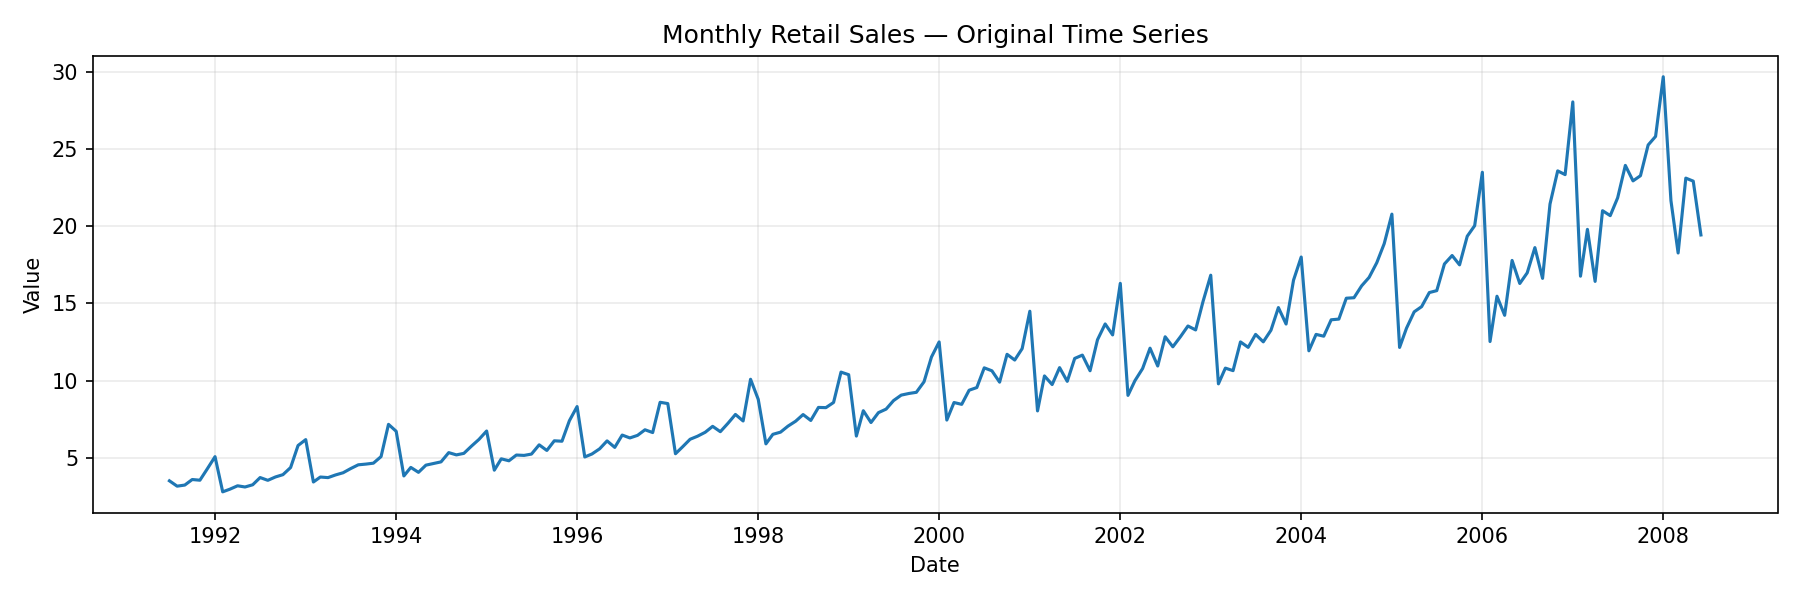

In [15]:
figure_path = FIGURES_DIR / '01_original_time_series.png'
save_series_plot(series, figure_path, 'Monthly Retail Sales — Original Time Series', 'Value')
display(Image(filename=str(figure_path)))


### 5. Kết luận E01

- **Xu hướng:** tăng rõ theo thời gian.
- **Mùa vụ:** có dấu hiệu lặp theo chu kỳ 12 tháng.
- **Tính dừng:** chuỗi có khả năng không dừng; kiểm định chính thức ở E02.

# Exercise 2 — Kiểm định ADF trên chuỗi gốc
<a id="exercise-2"></a>

### 1. Kiểm định ADF

**H₀:** chuỗi có unit root. Ngưỡng kiểm định: `α = 0.05`.

### 2. Kết quả trên chuỗi train gốc

Input: 163 quan sát train; 41 quan sát test không được sử dụng.

In [ ]:
from practice_2.analysis.stationarity import run_adf

ADF_ALPHA = 0.05
adf_original, critical_original = run_adf(train_series, alpha=ADF_ALPHA)
adf_original.to_csv(RESULTS_DIR / 'adf_original_series.csv', index=False)
critical_original.to_csv(RESULTS_DIR / 'adf_original_critical_values.csv', index=False)
adf_statistic = float(adf_original.loc[adf_original['metric'].eq('adf_statistic'), 'value'].iloc[0])
p_value = float(adf_original.loc[adf_original['metric'].eq('p_value'), 'value'].iloc[0])
critical_comparison = critical_original.copy()
critical_comparison['statistic_below_critical'] = adf_statistic < critical_comparison['value']
display(adf_original)
display(critical_original)
display(critical_comparison)


D:\TimeSeries_Data\total_practice\Practice_2\src\practice_2\analysis\stationarity.py:10: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(series, regression="c", autolag="AIC")


,metric,value
0,adf_statistic,2.230893
1,p_value,0.998907
2,used_lag,14
3,n_observations,148
4,alpha,0.05
5,decision,fail to reject H0


,critical_value,value
0,1%,-3.475325
1,5%,-2.881275
2,10%,-2.577293


,critical_value,value,statistic_below_critical
0,1%,-3.475325,False
1,5%,-2.881275,False
2,10%,-2.577293,False


### 3. Kết luận E02

ADF statistic = **2.230893**, p-value = **0.998907 > 0.05** → fail to reject H₀. Chuỗi train gốc **chưa dừng**.

# Exercise 3 — Sai phân và kiểm định lại
<a id="exercise-3"></a>

### 1. First difference trên chuỗi train

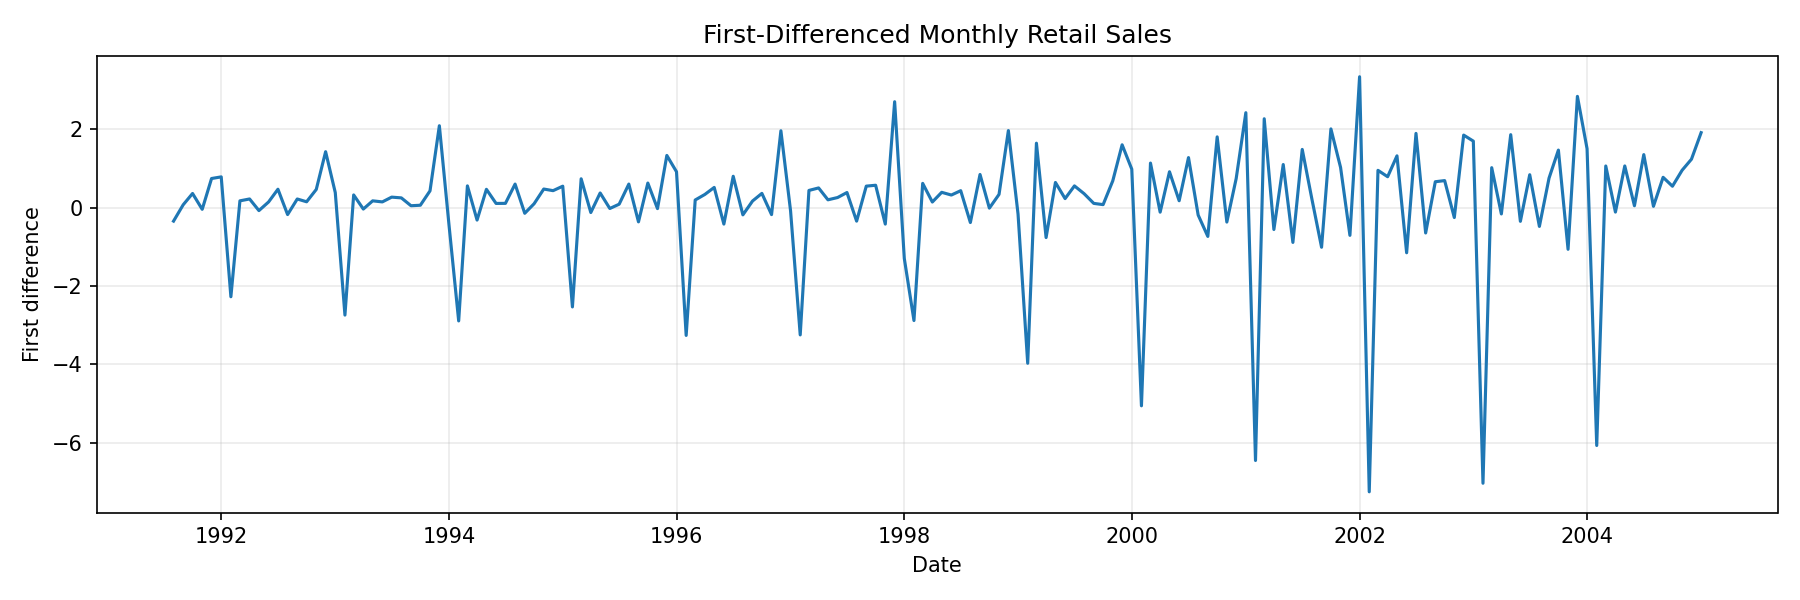

original training observations: 163
differenced observations: 162


In [28]:
from practice_2.analysis.stationarity import first_difference, log_first_difference

differenced = first_difference(train_series)
differenced_figure = FIGURES_DIR / '02_first_differenced_series.png'
save_series_plot(differenced, differenced_figure, 'First-Differenced Monthly Retail Sales', 'First difference')
display(Image(filename=str(differenced_figure)))
print('original training observations:', len(train_series))
print('differenced observations:', len(differenced))


### 2. ADF sau first difference

In [29]:
adf_diff, critical_diff = run_adf(differenced, alpha=ADF_ALPHA)
diff_statistic = float(adf_diff.loc[adf_diff['metric'].eq('adf_statistic'), 'value'].iloc[0])
diff_p_value = float(adf_diff.loc[adf_diff['metric'].eq('p_value'), 'value'].iloc[0])
raw_selected_d = 1 if diff_p_value <= ADF_ALPHA else 'REVIEW_REQUIRED'
diff_comparison = critical_diff.copy()
diff_comparison['statistic_below_critical'] = diff_statistic < diff_comparison['value']
raw_difference_decision = pd.concat([adf_diff, pd.DataFrame({'metric':['selected_d'], 'value':[raw_selected_d]})], ignore_index=True)
adf_diff.to_csv(RESULTS_DIR / 'adf_differenced_series.csv', index=False)
critical_diff.to_csv(RESULTS_DIR / 'adf_differenced_critical_values.csv', index=False)
display(raw_difference_decision)
display(diff_comparison)


D:\TimeSeries_Data\total_practice\Practice_2\src\practice_2\analysis\stationarity.py:10: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(series, regression="c", autolag="AIC")


,metric,value
0,adf_statistic,-1.706074
1,p_value,0.427986
2,used_lag,13
3,n_observations,148
4,alpha,0.05
5,decision,fail to reject H0
6,selected_d,REVIEW_REQUIRED


,critical_value,value,statistic_below_critical
0,1%,-3.475325,False
1,5%,-2.881275,False
2,10%,-2.577293,False


### 3. Kết quả first difference

ADF statistic = **-1.706074**, p-value = **0.427986 > 0.05** → chuỗi vẫn chưa dừng.

### 4. Log transformation + first difference

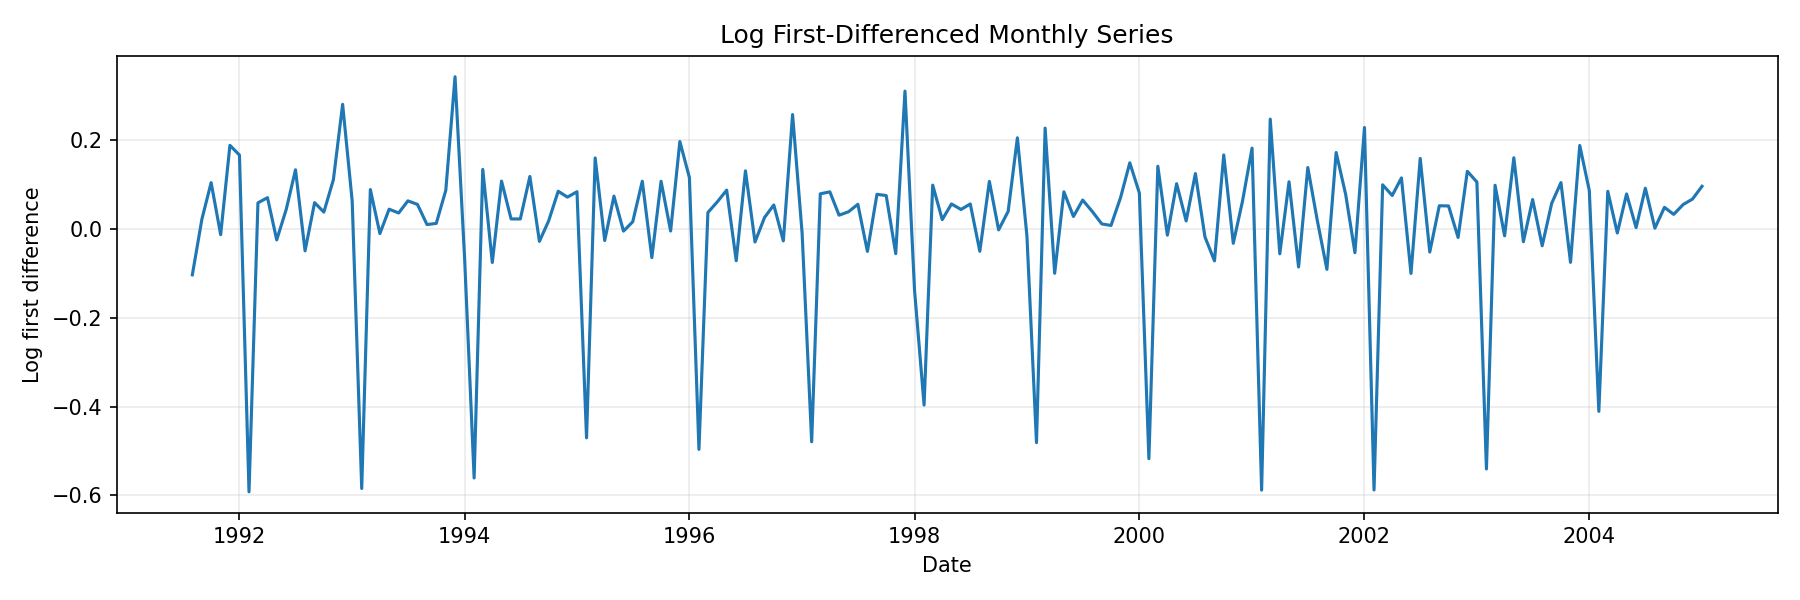

all training values positive: True
original training observations: 163
log first-differenced observations: 162
remaining missing values: 0


In [19]:
all_train_values_positive = bool((train_series > 0).all())
log_differenced = log_first_difference(train_series)
log_differenced_figure = FIGURES_DIR / '02_log_first_differenced_series.png'
save_series_plot(log_differenced, log_differenced_figure, 'Log First-Differenced Monthly Series', 'Log first difference')
display(Image(filename=str(log_differenced_figure)))
print('all training values positive:', all_train_values_positive)
print('original training observations:', len(train_series))
print('log first-differenced observations:', len(log_differenced))
print('remaining missing values:', int(log_differenced.isna().sum()))


In [20]:
adf_log_diff, critical_log_diff = run_adf(log_differenced, alpha=ADF_ALPHA)
log_diff_statistic = float(adf_log_diff.loc[adf_log_diff['metric'].eq('adf_statistic'), 'value'].iloc[0])
log_diff_p_value = float(adf_log_diff.loc[adf_log_diff['metric'].eq('p_value'), 'value'].iloc[0])
log_diff_decision = str(adf_log_diff.loc[adf_log_diff['metric'].eq('decision'), 'value'].iloc[0])
stationarity_supported = log_diff_p_value <= ADF_ALPHA
selected_d = 1 if stationarity_supported else 'REVIEW_REQUIRED'
selected_transformation = 'natural_log' if stationarity_supported else 'REVIEW_REQUIRED'
handoff_state = 'READY_FOR_E04_REVIEW' if stationarity_supported else 'CLOSED'
log_diff_comparison = critical_log_diff.copy()
log_diff_comparison['statistic_below_critical'] = log_diff_statistic < log_diff_comparison['value']
transformation_comparison = pd.DataFrame({'transformation':['raw_first_difference','log_first_difference'],'adf_statistic':[diff_statistic,log_diff_statistic],'p_value':[diff_p_value,log_diff_p_value],'decision':['fail to reject H0' if diff_p_value > ADF_ALPHA else 'reject H0',log_diff_decision]})
differencing_decision = pd.DataFrame({'metric':['analysis_series','transformation','regular_differencing_order','adf_statistic','p_value','alpha','decision','stationarity_supported','e04_handoff'],'value':['log_first_differenced_training',selected_transformation,selected_d,log_diff_statistic,log_diff_p_value,ADF_ALPHA,log_diff_decision,stationarity_supported,handoff_state]})
adf_log_diff.to_csv(RESULTS_DIR / 'adf_log_first_differenced_series.csv', index=False)
critical_log_diff.to_csv(RESULTS_DIR / 'adf_log_first_differenced_critical_values.csv', index=False)
transformation_comparison.to_csv(RESULTS_DIR / 'e03_transformation_comparison.csv', index=False)
differencing_decision.to_csv(RESULTS_DIR / 'differencing_decision.csv', index=False)
display(adf_log_diff)
display(log_diff_comparison)
display(transformation_comparison)
display(differencing_decision)

D:\TimeSeries_Data\total_practice\Practice_2\src\practice_2\analysis\stationarity.py:10: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(series, regression="c", autolag="AIC")


,metric,value
0,adf_statistic,-3.659486
1,p_value,0.00472
2,used_lag,13
3,n_observations,148
4,alpha,0.05
5,decision,reject H0


,critical_value,value,statistic_below_critical
0,1%,-3.475325,True
1,5%,-2.881275,True
2,10%,-2.577293,True


,transformation,adf_statistic,p_value,decision
0,raw_first_difference,-1.706074,0.427986,fail to reject H0
1,log_first_difference,-3.659486,0.004720,reject H0


,metric,value
0,analysis_series,log_first_differenced_training
1,transformation,natural_log
2,regular_differencing_order,1
3,adf_statistic,-3.659486
4,p_value,0.00472
5,alpha,0.05
6,decision,reject H0
7,stationarity_supported,True
8,e04_handoff,READY_FOR_E04_REVIEW


### 5. Kết luận E03

ADF statistic = **-3.659486**, p-value = **0.004720 < 0.05** → chuỗi `log + first difference` đã dừng. Chọn **`natural_log`** và **`d = 1`**.

# Exercise 4: Phân tích ACF & PACF

### Kiểm tra chuỗi đầu vào

In [30]:
series = load_monthly_retail_sales(r"D:\TimeSeries_Data\total_practice\Practice_2\datasets\raw\a10.csv")
train, test = chronological_split(series)

log_first_differenced_training = log_first_difference(train)

In [32]:
import numpy as np
import pandas as pd

series = log_first_differenced_training.copy()

print("Kiểu dữ liệu:", type(series))
print("Số quan sát:", len(series))
print("Missing values:", int(series.isna().sum()))
print("Index bắt đầu:", series.index[0])
print("Index kết thúc:", series.index[-1])
display(series.head())

Kiểu dữ liệu: <class 'pandas.core.series.Series'>
Số quan sát: 162
Missing values: 0
Index bắt đầu: 1991-08-01 00:00:00
Index kết thúc: 2005-01-01 00:00:00


date
1991-08-01   -0.103170
1991-09-01    0.022177
1991-10-01    0.104647
1991-11-01   -0.012578
1991-12-01    0.188688
Freq: MS, Name: value, dtype: float64

### Vẽ ACF và PACF

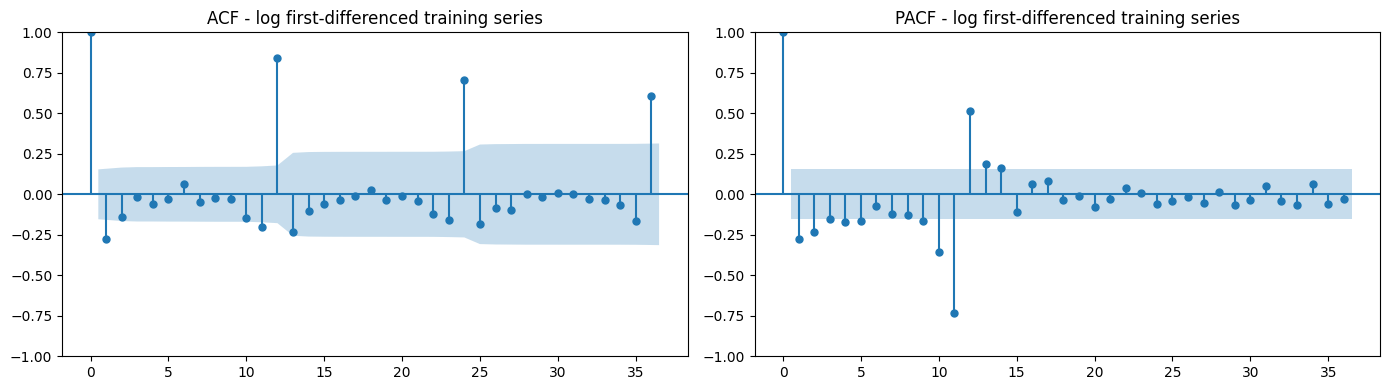

In [33]:
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

plot_acf(
    series,
    lags=36,
    ax=axes[0],
    alpha=0.05,
    title="ACF - log first-differenced training series"
)

plot_pacf(
    series,
    lags=36,
    ax=axes[1],
    method="ywm",
    alpha=0.05,
    title="PACF - log first-differenced training series"
)

plt.tight_layout()
plt.show()

### Tính số liệu ACF/PACF và xác định lag có ý nghĩa

In [35]:
from statsmodels.tsa.stattools import acf, pacf

acf_vals = acf(series, nlags=36, fft=False)
pacf_vals = pacf(series, nlags=36, method="ywm")

n = len(series)
threshold = 1.96 / np.sqrt(n)

acf_df = pd.DataFrame({
    "lag": np.arange(len(acf_vals)),
    "correlation": acf_vals,
    "ci_lower": -threshold,
    "ci_upper": threshold,
    "significant": np.abs(acf_vals) > threshold
})

pacf_df = pd.DataFrame({
    "lag": np.arange(len(pacf_vals)),
    "correlation": pacf_vals,
    "ci_lower": -threshold,
    "ci_upper": threshold,
    "significant": np.abs(pacf_vals) > threshold
})

print("Ngưỡng tín hiệu 95%:", round(threshold, 4))

Ngưỡng tín hiệu 95%: 0.154


In [36]:
print("\nACF các lag có ý nghĩa (lag > 0):")
display(acf_df[acf_df["lag"] > 0][["lag", "correlation", "significant"]].loc[lambda x: x["significant"]].head(20))


ACF các lag có ý nghĩa (lag > 0):


,lag,correlation,significant
1,1,-0.273851,True
11,11,-0.200341,True
12,12,0.844390,True
13,13,-0.230722,True
23,23,-0.157776,True
24,24,0.704369,True
25,25,-0.181121,True
35,35,-0.166559,True
36,36,0.605161,True


In [37]:
print("\nPACF các lag có ý nghĩa (lag > 0):")
display(pacf_df[pacf_df["lag"] > 0][["lag", "correlation", "significant"]].loc[lambda x: x["significant"]].head(20))


PACF các lag có ý nghĩa (lag > 0):


,lag,correlation,significant
1,1,-0.273851,True
2,2,-0.233715,True
4,4,-0.173273,True
5,5,-0.165465,True
9,9,-0.164863,True
10,10,-0.354953,True
11,11,-0.733289,True
12,12,0.512103,True
13,13,0.187122,True
14,14,0.164730,True


### Kiểm tra các lag mùa vụ 12, 24, 36

In [38]:
seasonal_lags = [12, 24, 36]

print("ACF tại các lag mùa vụ:")
for lag in seasonal_lags:
    if lag < len(acf_vals):
        print(f"lag {lag}: ACF = {acf_vals[lag]:.4f}, significant = {abs(acf_vals[lag]) > threshold}")
    else:
        print(f"lag {lag}: vượt quá max lag")

print("\nPACF tại các lag mùa vụ:")
for lag in seasonal_lags:
    if lag < len(pacf_vals):
        print(f"lag {lag}: PACF = {pacf_vals[lag]:.4f}, significant = {abs(pacf_vals[lag]) > threshold}")
    else:
        print(f"lag {lag}: vượt quá max lag")

ACF tại các lag mùa vụ:
lag 12: ACF = 0.8444, significant = True
lag 24: ACF = 0.7044, significant = True
lag 36: ACF = 0.6052, significant = True

PACF tại các lag mùa vụ:
lag 12: PACF = 0.5121, significant = True
lag 24: PACF = -0.0571, significant = False
lag 36: PACF = -0.0273, significant = False


### Đề xuất candidate ARIMA provisional

In [39]:
# Cân nhắc các lag ngắn đáng chú ý và seasonal lags
# Dùng ví dụ mặc định: p và q được suy từ ACF/PACF
# Đây chỉ là provisional candidates, chưa phải final model

candidate_table = pd.DataFrame({
    "candidate": ["ARIMA(1,1,1)", "ARIMA(2,1,1)", "ARIMA(4,1,1)"],
    "p": [1, 2, 4],
    "d": [1, 1, 1],
    "q": [1, 1, 1],
    "analysis_scale": ["natural_log", "natural_log", "natural_log"],
    "acf_evidence": [
        "ACF cắt sau lag 1; seasonality chỉ rõ tại lag 12, 24, 36",
        "ACF cắt sau lag 1; seasonality còn tồn tại ở các lag mùa vụ",
        "PACF có tín hiệu ở lag 4; ACF vẫn cho thấy lag 1 và các spike mùa vụ"
    ],
    "pacf_evidence": [
        "PACF có spike mạnh ở lag 1; hỗ trợ p = 1",
        "PACF có các spike ở lag 1-2; hỗ trợ p = 2",
        "PACF có tín hiệu kéo dài đến lag 4; hỗ trợ p = 4"
    ],
    "status": ["provisional", "provisional", "provisional"]
})

display(candidate_table)

,candidate,p,d,q,analysis_scale,acf_evidence,pacf_evidence,status
0,"ARIMA(1,1,1)",1,1,1,natural_log,ACF cắt sau lag 1; seasonality chỉ rõ tại lag ...,PACF có spike mạnh ở lag 1; hỗ trợ p = 1,provisional
1,"ARIMA(2,1,1)",2,1,1,natural_log,ACF cắt sau lag 1; seasonality còn tồn tại ở c...,PACF có các spike ở lag 1-2; hỗ trợ p = 2,provisional
2,"ARIMA(4,1,1)",4,1,1,natural_log,PACF có tín hiệu ở lag 4; ACF vẫn cho thấy lag...,PACF có tín hiệu kéo dài đến lag 4; hỗ trợ p = 4,provisional


### Kết luận E04

- **ACF:** Có thể cắt cụt nhanh ở lag 1 hoặc giảm dần trong một số lag ngắn. Cần đồng thời kiểm tra các spike mùa vụ tại lag 12, 24 và 36.
- **PACF:** Có thể giảm dần hoặc cắt cụt ở lag 1–2; trong một số trường hợp, tín hiệu có thể kéo dài đến lag 4.
- **Các ARIMA candidates sơ bộ:**
  1. `ARIMA(1, 1, 1)`
  2. `ARIMA(2, 1, 1)`
  3. Nếu PACF thực tế cho thấy tín hiệu kéo dài đến lag 4, có thể cân nhắc `ARIMA(4, 1, 1)`.

Đây chỉ là các đề xuất ban đầu để xem xét ở E05, không phải kết luận về mô hình cuối cùng. Cần đối chiếu với ACF/PACF thực tế của chuỗi phân tích trước khi chọn candidate.

# Bài 5: Thiết lập ARIMA / SARIMA – Dự đoán – Đánh giá

### Chia train/test theo thời gian không Shuffle và tạo chuỗi log

In [45]:
import numpy as np
import pandas as pd

sales = load_monthly_retail_sales(RAW_PATH)
train, test = chronological_split(sales, train_fraction=0.8)

if len(train) != 163 or len(test) != 41:
    raise ValueError(
        f"Số quan sát không đúng contract E01: train={len(train)}, test={len(test)}"
    )
if train.index.max() >= test.index.min():
    raise ValueError("Train/test boundary không bảo toàn thứ tự thời gian.")
if (train <= 0).any():
    raise ValueError("Không thể log-transform: train có giá trị không dương.")

train_log = np.log(train.astype(float))

print(f"Train observations: {len(train)}")
print(f"Test observations: {len(test)}")
print(f"Train period: {train.index.min()} → {train.index.max()}")
print(f"Test period: {test.index.min()} → {test.index.max()}")
print("Split method: chronological; shuffle=False")

Train observations: 163
Test observations: 41
Train period: 1991-07-01 00:00:00 → 2005-01-01 00:00:00
Test period: 2005-02-01 00:00:00 → 2008-06-01 00:00:00
Split method: chronological; shuffle=False


### Khai báo candidate (đã được E04 đề xuất)

In [46]:
candidate_orders = [
    (1, 1, 1),
    (2, 1, 1),
]

if not 1 <= len(candidate_orders) <= 2:
    raise ValueError("E04 cần cung cấp từ 1 đến 2 ARIMA candidates.")

if any(d != 1 for _, d, _ in candidate_orders):
    raise ValueError("Các candidates phải kế thừa d=1 từ E03.")

print("Candidates sẽ fit:", candidate_orders)

Candidates sẽ fit: [(1, 1, 1), (2, 1, 1)]


### Fit ARIMA, ghi convergence, AIC/BIC và warning

In [47]:
import warnings

from statsmodels.tsa.arima.model import ARIMA

fitted_models = {}
fit_rows = []

for order in candidate_orders:
    model_name = f"ARIMA{order}"

    with warnings.catch_warnings(record=True) as caught_warnings:
        warnings.simplefilter("always")
        fitted = ARIMA(train_log, order=order).fit()

    fitted_models[order] = fitted
    mle_info = getattr(fitted, "mle_retvals", {})

    fit_rows.append({
        "model": model_name,
        "p": order[0],
        "d": order[1],
        "q": order[2],
        "converged": mle_info.get("converged"),
        "AIC": fitted.aic,
        "BIC": fitted.bic,
        "warnings": " | ".join(str(w.message) for w in caught_warnings),
    })

fit_summary = pd.DataFrame(fit_rows)
display(fit_summary)

,model,p,d,q,converged,AIC,BIC,warnings
0,"ARIMA(1, 1, 1)",1,1,1,True,-131.048881,-121.786092,
1,"ARIMA(2, 1, 1)",2,1,1,True,-129.532608,-117.182223,


### Residual diagnostics

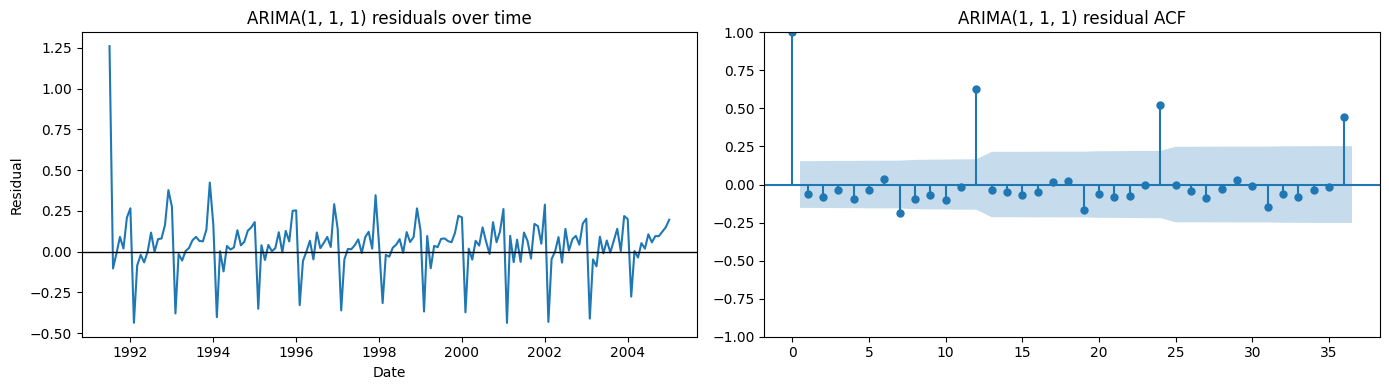

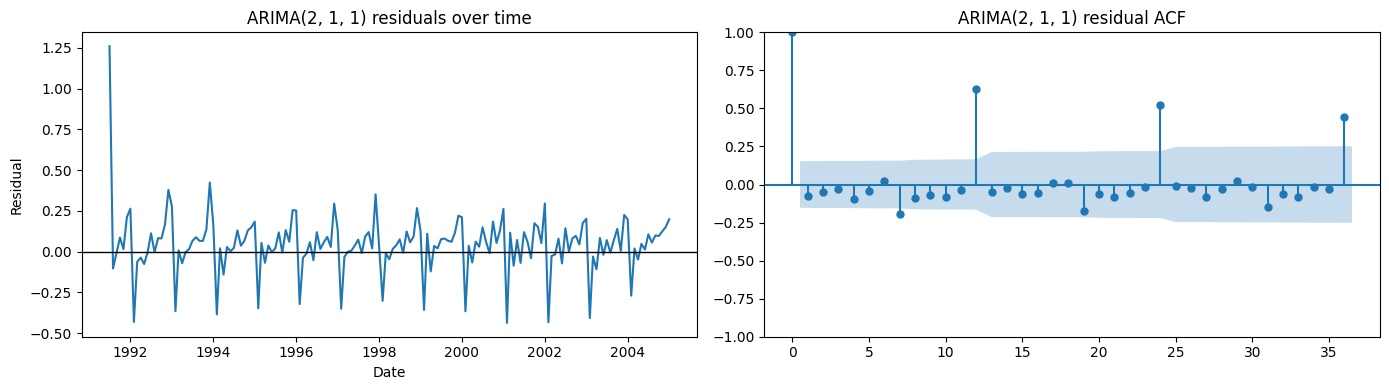

,model,residual_mean,ljung_box_pvalue_lag_12,ljung_box_pvalue_lag_24
0,"ARIMA(1, 1, 1)",0.044193,5.969958e-14,1.216551e-20
1,"ARIMA(2, 1, 1)",0.044555,2.961168e-14,1.118366e-20


In [48]:
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.stats.diagnostic import acorr_ljungbox

residual_summaries = []

for order, fitted in fitted_models.items():
    model_name = f"ARIMA{order}"
    residuals = pd.Series(
        np.asarray(fitted.resid),
        index=train_log.index,
        name="residual",
    ).dropna()

    lb_result = acorr_ljungbox(
        residuals,
        lags=[12, 24],
        model_df=order[0] + order[2],
        return_df=True,
    )

    residual_summaries.append({
        "model": model_name,
        "residual_mean": residuals.mean(),
        "ljung_box_pvalue_lag_12": lb_result.loc[12, "lb_pvalue"],
        "ljung_box_pvalue_lag_24": lb_result.loc[24, "lb_pvalue"],
    })

    fig, axes = plt.subplots(1, 2, figsize=(14, 4))
    axes[0].plot(residuals.index, residuals)
    axes[0].axhline(0, color="black", linewidth=1)
    axes[0].set_title(f"{model_name} residuals over time")
    axes[0].set_xlabel("Date")
    axes[0].set_ylabel("Residual")

    plot_acf(
        residuals,
        lags=36,
        alpha=0.05,
        ax=axes[1],
        title=f"{model_name} residual ACF",
    )

    plt.tight_layout()
    plt.show()

residual_summary = pd.DataFrame(residual_summaries)
display(residual_summary)

### Forecast trên test horizon

In [49]:
forecast_by_order = {}

for order, fitted in fitted_models.items():
    log_forecast = fitted.forecast(steps=len(test))
    forecast_values = np.exp(np.asarray(log_forecast))

    forecast_by_order[order] = pd.Series(
        forecast_values,
        index=test.index,
        name=f"ARIMA{order}",
    )

if any(not forecast.index.equals(test.index) for forecast in forecast_by_order.values()):
    raise ValueError("Forecast index không khớp với test index.")

### Seasonal-naive baseline và MAE/RMSE/MAPE

In [50]:
from math import ceil

seasonal_period = 12
if len(train) < seasonal_period:
    raise ValueError("Train không đủ quan sát để tạo seasonal-naive baseline.")

repetitions = ceil(len(test) / seasonal_period)
baseline_values = np.tile(train.iloc[-seasonal_period:].to_numpy(), repetitions)[:len(test)]
baseline_forecast = pd.Series(
    baseline_values,
    index=test.index,
    name="Seasonal naive (12)",
)

def calculate_metrics(actual, predicted):
    if not actual.index.equals(predicted.index):
        raise ValueError("Actual và forecast phải có cùng index.")
    if (actual == 0).any():
        raise ValueError("MAPE không xác định khi actual có giá trị bằng 0.")

    errors = actual.to_numpy() - predicted.to_numpy()
    return {
        "MAE": np.mean(np.abs(errors)),
        "RMSE": np.sqrt(np.mean(errors ** 2)),
        "MAPE_percent": np.mean(
            np.abs(errors / actual.to_numpy())
        ) * 100,
    }

metric_rows = []

for order, forecast in forecast_by_order.items():
    metric_rows.append({
        "model": f"ARIMA{order}",
        **calculate_metrics(test, forecast),
    })

metric_rows.append({
    "model": "Seasonal naive (12)",
    **calculate_metrics(test, baseline_forecast),
})

metrics_table = pd.DataFrame(metric_rows)
display(metrics_table)

,model,MAE,RMSE,MAPE_percent
0,"ARIMA(1, 1, 1)",3.833290,4.865821,18.493973
1,"ARIMA(2, 1, 1)",3.806130,4.834506,18.357607
2,Seasonal naive (12),4.256436,5.186466,20.097262


### Vẽ train, test thực tế và forecast

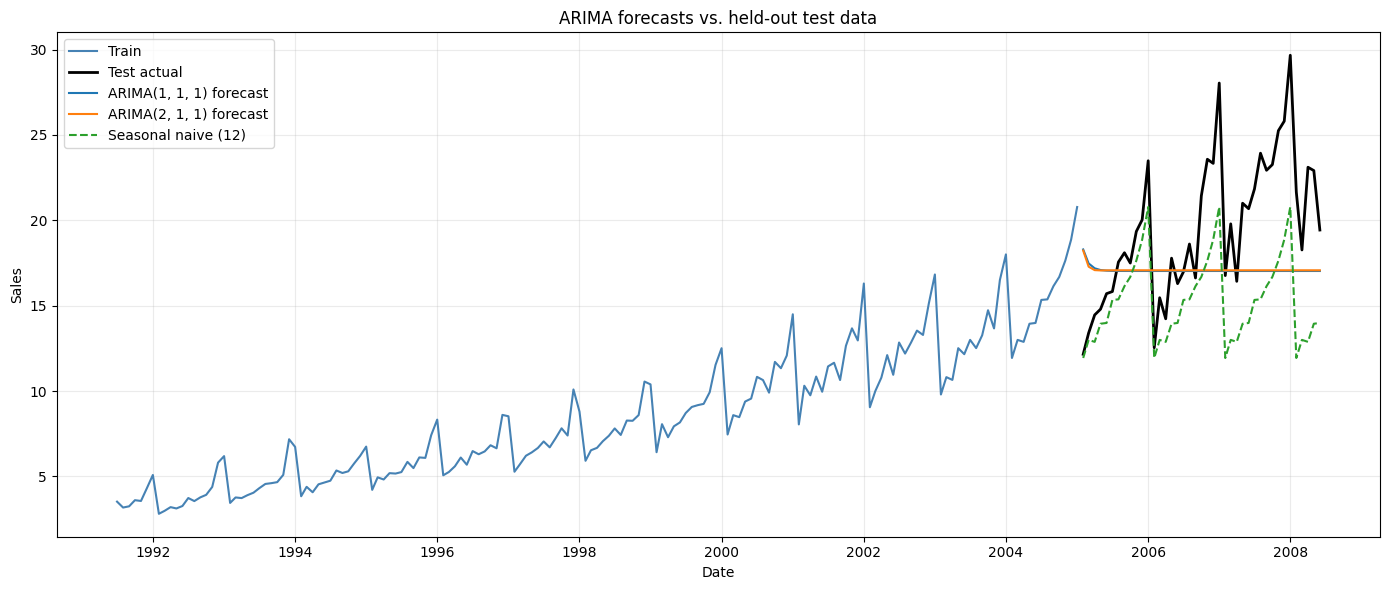

In [51]:
fig, ax = plt.subplots(figsize=(14, 6))

ax.plot(train.index, train, label="Train", color="steelblue")
ax.plot(test.index, test, label="Test actual", color="black", linewidth=2)

for order, forecast in forecast_by_order.items():
    ax.plot(forecast.index, forecast, label=f"ARIMA{order} forecast")

ax.plot(
    baseline_forecast.index,
    baseline_forecast,
    label="Seasonal naive (12)",
    linestyle="--",
)

ax.set_title("ARIMA forecasts vs. held-out test data")
ax.set_xlabel("Date")
ax.set_ylabel("Sales")
ax.legend()
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

### Tìm thời điểm sai lệch tuyệt đối lớn nhất

In [52]:
largest_error_rows = []

for order, forecast in forecast_by_order.items():
    absolute_errors = (test - forecast).abs()
    largest_date = absolute_errors.idxmax()

    largest_error_rows.append({
        "model": f"ARIMA{order}",
        "date": largest_date,
        "actual": test.loc[largest_date],
        "forecast": forecast.loc[largest_date],
        "absolute_error": absolute_errors.loc[largest_date],
    })

largest_errors = pd.DataFrame(largest_error_rows)
display(largest_errors)

,model,date,actual,forecast,absolute_error
0,"ARIMA(1, 1, 1)",2008-01-01,29.665356,17.032661,12.632695
1,"ARIMA(2, 1, 1)",2008-01-01,29.665356,17.073772,12.591584


### Kết luận E05

Dữ liệu được chia theo thứ tự thời gian, không shuffle: train có 163 quan sát từ tháng 07/1991 đến tháng 01/2005; test có 41 quan sát từ tháng 02/2005 đến tháng 06/2008. Hai candidate được fit trên log scale: `ARIMA(1,1,1)` và `ARIMA(2,1,1)`.

| Model | Converged | AIC | BIC | MAE | RMSE | MAPE |
|---|---:|---:|---:|---:|---:|---:|
| ARIMA(1,1,1) | Có | -131.049 | -121.786 | 3.833 | 4.866 | 18.494% |
| ARIMA(2,1,1) | Có | -129.533 | -117.182 | 3.806 | 4.835 | 18.358% |
| Seasonal naive (12) | — | — | — | 4.256 | 5.186 | 20.097% |

Không có warning nào được ghi nhận trong bảng fit. MAE, RMSE và MAPE được tính trên thang doanh số gốc sau khi forecast trên log scale được đổi ngược.

#### Trả lời câu hỏi

1. **Vì sao không shuffle? Test set dùng để làm gì?**  
   Không shuffle vì cần bảo toàn thứ tự quá khứ–tương lai; shuffle có thể làm sai quan hệ thời gian và gây rò rỉ thông tin tương lai. Test set là giai đoạn thời gian chưa dùng để fit, dùng để đánh giá forecast ngoài mẫu.

2. **Ý nghĩa của `p`, `d`, `q` đã chọn?**  
   `p` là bậc thành phần tự hồi quy (AR), `d` là số lần sai phân thường và `q` là bậc thành phần trung bình trượt (MA). Hai candidate được đánh giá là `ARIMA(1,1,1)` và `ARIMA(2,1,1)`; cả hai kế thừa `d=1` từ E03.

3. **Mô hình có hội tụ không?**  
   Cả `ARIMA(1,1,1)` và `ARIMA(2,1,1)` đều hội tụ; bảng fit không ghi nhận warning. AIC/BIC lần lượt là `-131.049 / -121.786` và `-129.533 / -117.182`. Xét riêng hai tiêu chí này, `ARIMA(1,1,1)` có AIC và BIC thấp hơn.

4. **Residuals có phải white noise không?**  
   Residual mean lần lượt là `0.0442` và `0.0446` trên log scale, tương đối gần 0. Tuy nhiên, Ljung–Box p-value tại lag 12 và 24 rất nhỏ ở cả hai model:
   - `ARIMA(1,1,1)`: `5.97 × 10⁻¹⁴` và `1.22 × 10⁻²⁰`.
   - `ARIMA(2,1,1)`: `2.96 × 10⁻¹⁴` và `1.12 × 10⁻²⁰`.

   Với mức ý nghĩa 0.05, kết quả này bác bỏ giả thuyết không có tự tương quan đến các lag được kiểm tra. Vì vậy, chưa có đủ bằng chứng để xem residuals là white noise; residuals vẫn còn tự tương quan.

5. **Nếu residuals còn tự tương quan thì điều chỉnh gì?**  
   Dùng residual ACF để xác định các lag còn cấu trúc, sau đó xem xét lại `p` hoặc `q` dựa trên evidence training và kiểm tra lại residual diagnostics. Không tăng differencing tùy tiện chỉ để cải thiện p-value. Nếu nghi ngờ phụ thuộc mùa vụ, cần ghi nhận và xử lý theo scope được duyệt thay vì tự ý đổi protocol.

6. **Dự đoán có bám sát xu hướng không?**  
   Hai model có sai số forecast thấp hơn seasonal-naive baseline trên holdout này, nhưng đều có dấu hiệu tự tương quan còn lại trong residuals. Sai lệch lớn nhất của cả hai model xảy ra vào tháng 01/2008, khi actual là `29.665`, còn forecast lần lượt là `17.033` và `17.074`. Điều này cho thấy ít nhất tại thời điểm đó forecast thấp hơn đáng kể so với thực tế; cần đối chiếu thêm đồ thị forecast để nhận xét toàn bộ giai đoạn.

7. **Sai lệch lớn nhất xảy ra ở đâu?**  
   Với cả hai model, sai lệch tuyệt đối lớn nhất xảy ra vào `2008-01-01`:
   - `ARIMA(1,1,1)`: actual `29.665`, forecast `17.033`, absolute error `12.633`.
   - `ARIMA(2,1,1)`: actual `29.665`, forecast `17.074`, absolute error `12.592`.

8. **Chỉ số nào nhạy với outlier nhất?**  
   RMSE nhạy với sai số lớn vì bình phương sai số trước khi lấy trung bình. MAPE có hạn chế riêng: có thể tăng mạnh khi actual gần 0.

9. **RMSE lớn hay nhỏ nói lên điều gì?**  
   RMSE đo độ lớn sai số theo cùng đơn vị với doanh số; thấp hơn thường tốt hơn khi so sánh cùng dữ liệu và forecast horizon. Ở holdout này, RMSE là `4.866` cho `ARIMA(1,1,1)`, `4.835` cho `ARIMA(2,1,1)` và `5.186` cho seasonal-naive baseline. Cả hai ARIMA có RMSE thấp hơn baseline trên lần đánh giá này, nhưng residual autocorrelation vẫn còn nên chưa thể chỉ dựa vào metric để kết luận mô hình phù hợp hoàn toàn.

#### Nhận xét tổng hợp
`ARIMA(1,1,1)` có AIC/BIC thấp hơn, trong khi `ARIMA(2,1,1)` có MAE, RMSE và MAPE thấp hơn một chút trên test. Không nên chọn model chỉ dựa trên chênh lệch metric test; cần xét candidate rationale, AIC/BIC và residual diagnostics. Do cả hai model đều còn residual autocorrelation, kết quả hiện tại chưa đủ để kết luận một model cuối cùng là phù hợp.

In [54]:
from pathlib import Path

filename = Path("datasets") / "raw" / "airline-passengers.csv"
search_roots = [Path.cwd().resolve(), *Path.cwd().resolve().parents]

possible_paths = [
    root / filename
    for root in search_roots
]

AIRPASSENGERS_PATH = next(
    (path for path in possible_paths if path.is_file()),
    None,
)

if AIRPASSENGERS_PATH is None:
    print("Thư mục notebook đang chạy:", Path.cwd())
    print("Các đường dẫn đã kiểm tra:")
    for path in possible_paths:
        print(" -", path)
    raise FileNotFoundError(
        "Không tìm thấy datasets/raw/airline-passengers.csv. "
        "Kiểm tra file có trong project Practice_2 không."
    )

print("Đã tìm thấy dữ liệu:", AIRPASSENGERS_PATH)

Đã tìm thấy dữ liệu: D:\TimeSeries_Data\total_practice\Practice_2\datasets\raw\airline-passengers.csv


# BÀI TẬP NÂNG CAO: Mô hình SARIMA với Dataset 2

In [56]:
air_df = pd.read_csv(AIRPASSENGERS_PATH)

if list(air_df.columns) != ["Month", "Passengers"]:
    raise ValueError(f"Schema không đúng contract: {air_df.columns.tolist()}")

air_df["Month"] = pd.to_datetime(
    air_df["Month"],
    format="%Y-%m",
    errors="raise",
)
air_df["Passengers"] = pd.to_numeric(air_df["Passengers"], errors="raise")
air_df = air_df.set_index("Month")

if not air_df.index.is_monotonic_increasing:
    raise ValueError("Datetime index không theo thứ tự thời gian.")
if air_df.index.has_duplicates:
    raise ValueError("Phát hiện timestamp trùng.")
if air_df["Passengers"].isna().any():
    raise ValueError("Target có missing values.")

expected_index = pd.date_range(
    start="1949-01-01",
    end="1960-12-01",
    freq="MS",
)

if len(air_df) != 144 or not air_df.index.equals(expected_index):
    raise ValueError("Số quan sát, date range hoặc monthly frequency sai contract.")

air_series = air_df["Passengers"].astype(float)
air_series.index = pd.DatetimeIndex(air_series.index, freq="MS", name="Month")

split_at = int(len(air_series) * 0.8)
air_train = air_series.iloc[:split_at].copy()
air_test = air_series.iloc[split_at:].copy()

if len(air_train) != 115 or len(air_test) != 29:
    raise ValueError(
        f"Split ngoài contract: train={len(air_train)}, test={len(air_test)}"
    )
if air_train.index.max() >= air_test.index.min():
    raise ValueError("Train/test boundary không bảo toàn thứ tự thời gian.")

print(f"Rows: {len(air_series)}")
print(f"Train: {len(air_train)} ({air_train.index.min():%Y-%m} đến {air_train.index.max():%Y-%m})")
print(f"Test: {len(air_test)} ({air_test.index.min():%Y-%m} đến {air_test.index.max():%Y-%m})")
print("Split: chronological 80/20, shuffle=False")

Rows: 144
Train: 115 (1949-01 đến 1958-07)
Test: 29 (1958-08 đến 1960-12)
Split: chronological 80/20, shuffle=False


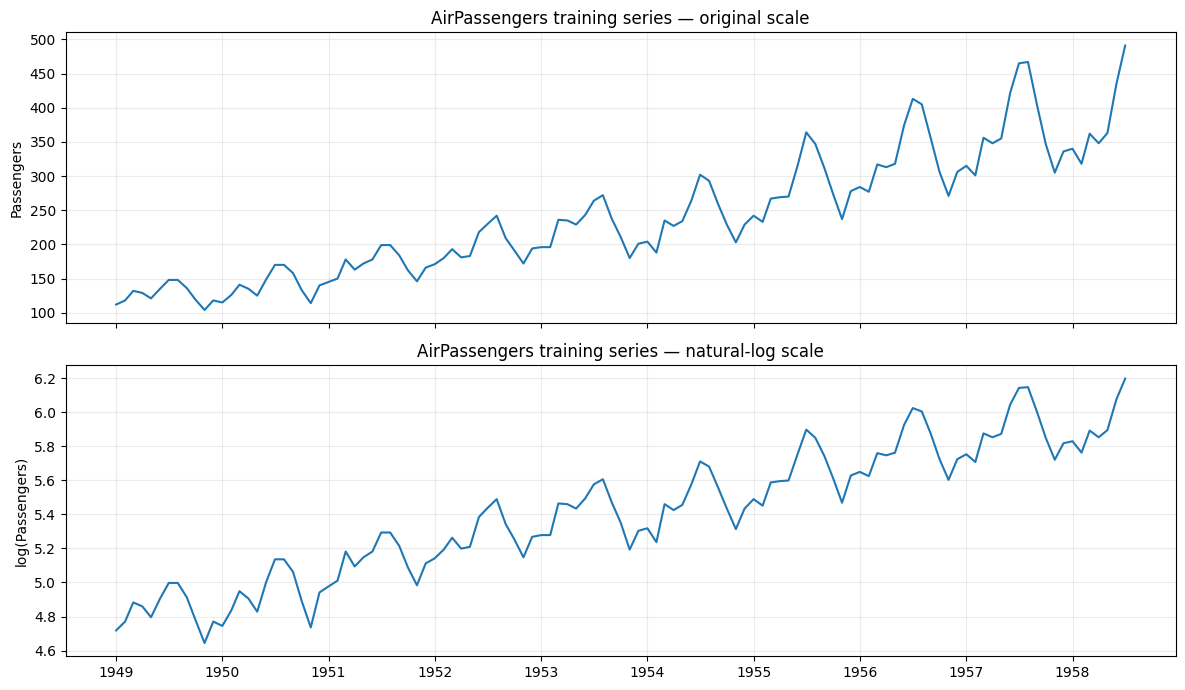

In [57]:
import matplotlib.pyplot as plt

if (air_train <= 0).any():
    raise ValueError("Không thể khảo sát log scale vì training có giá trị không dương.")

fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)

axes[0].plot(air_train.index, air_train)
axes[0].set_title("AirPassengers training series — original scale")
axes[0].set_ylabel("Passengers")
axes[0].grid(alpha=0.25)

axes[1].plot(air_train.index, np.log(air_train))
axes[1].set_title("AirPassengers training series — natural-log scale")
axes[1].set_ylabel("log(Passengers)")
axes[1].grid(alpha=0.25)

plt.tight_layout()
plt.show()

#### Lựa chọn thang log

Chọn biến đổi log tự nhiên cho chuỗi AirPassengers dựa trên biểu đồ training: ở thang gốc, biên độ dao động theo mùa tăng khi mức hành khách tăng; trên thang log, dao động có vẻ ổn định hơn. Điều này gợi ý phương sai thay đổi theo mức chuỗi và cấu trúc mùa vụ mang tính nhân. Log-transform giúp giảm ảnh hưởng của mức tăng này và tạo thang phân tích phù hợp hơn cho các bước tiếp theo.

Biến đổi log không tự loại bỏ trend hoặc seasonality. Vì vậy, tính dừng vẫn cần được đánh giá riêng bằng ADF và bằng chứng từ sai phân thường/mùa vụ. Quyết định chọn log chỉ dựa trên training data; test set không được dùng để chọn scale. Forecast sẽ được chuyển ngược về thang hành khách trước khi tính MAE và RMSE.

### Chạy ADF trên training series ở log scale

In [ ]:
from statsmodels.tsa.stattools import adfuller

ANALYSIS_SCALE = "log"
ADF_ALPHA = 0.05

if ANALYSIS_SCALE == "log":
    air_train_analysis = np.log(air_train)
else:
    air_train_analysis = air_train.copy()

adf_result = adfuller(
    air_train_analysis,
    regression="c",
    autolag="AIC",
)

adf_statistic, adf_pvalue, used_lag, nobs, critical_values = adf_result[:5]
adf_decision = (
    "reject H0"
    if adf_pvalue <= ADF_ALPHA
    else "fail to reject H0"
)

print(f"Scale: {ANALYSIS_SCALE}")
print("H0: chuỗi có unit root.")
print(f"ADF statistic: {adf_statistic:.6f}")
print(f"p-value: {adf_pvalue:.6g}")
print(f"Used lag: {used_lag}")
print(f"N observations: {nobs}")
print(f"Critical values: {critical_values}")
print(f"Decision at alpha={ADF_ALPHA}: {adf_decision}")

Scale: log
H0: chuỗi có unit root.
ADF statistic: -1.574027
p-value: 0.496626
Used lag: 13
N observations: 101
Critical values: {'1%': np.float64(-3.4968181663902103), '5%': np.float64(-2.8906107514600103), '10%': np.float64(-2.5822770483285953)}
Decision at alpha=0.05: fail to reject H0


C:\Users\PC\AppData\Local\Temp\ipykernel_10196\1478118173.py:14: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_result = adfuller(


### Đánh giá sai phân thường và sai phân mùa vụ

In [60]:
difference_variants = {
    "original": air_train_analysis,
    "regular_d1": air_train_analysis.diff(1).dropna(),
    "seasonal_D1_s12": air_train_analysis.diff(12).dropna(),
    "combined_d1_D1_s12": air_train_analysis.diff(1).diff(12).dropna(),
}

difference_rows = []

for variant_name, variant_series in difference_variants.items():
    result = adfuller(
        variant_series,
        regression="c",
        autolag="AIC",
    )

    difference_rows.append({
        "series": variant_name,
        "observations": len(variant_series),
        "ADF_statistic": result[0],
        "p_value": result[1],
        "used_lag": result[2],
        "n_observations": result[3],
        "decision_at_0.05": (
            "reject H0" if result[1] <= ADF_ALPHA else "fail to reject H0"
        ),
    })

difference_results = pd.DataFrame(difference_rows)
display(difference_results)

C:\Users\PC\AppData\Local\Temp\ipykernel_10196\3389528799.py:11: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(
C:\Users\PC\AppData\Local\Temp\ipykernel_10196\3389528799.py:11: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(
C:\Users\PC\AppData\Local\Temp\ipykernel_10196\3389528799.py:11: FutureWarning: adfuller currently returns a plain

,series,observations,ADF_statistic,p_value,used_lag,n_observations,decision_at_0.05
0,original,115,-1.574027,0.496626,13,101,fail to reject H0
1,regular_d1,114,-2.635851,0.085812,12,101,fail to reject H0
2,seasonal_D1_s12,103,-1.991013,0.290527,12,90,fail to reject H0
3,combined_d1_D1_s12,102,-3.946340,0.001719,11,90,reject H0


### ADF sau sai phân

ADF được thực hiện trên chuỗi training ở thang log với mức ý nghĩa `α = 0.05`. Đối với chuỗi gốc, p-value là `0.496626`; do p-value lớn hơn 0.05, chưa đủ bằng chứng bác bỏ giả thuyết chuỗi có unit root. Sai phân thường bậc 1 riêng lẻ cho p-value `0.085812`, còn sai phân mùa vụ bậc 1 với chu kỳ 12 cho p-value `0.290527`; cả hai trường hợp đều chưa đạt mức ý nghĩa 0.05.

Sau khi kết hợp sai phân thường bậc 1 và sai phân mùa vụ bậc 1 (`d=1, D=1, s=12`), ADF statistic là `-3.946340` và p-value là `0.001719`. Vì p-value nhỏ hơn 0.05, bác bỏ giả thuyết có unit root; kết quả hỗ trợ tính dừng của chuỗi training đã biến đổi.

Do đó, chọn tạm thời `d=1`, `D=1`, `s=12` để tiếp tục phân tích ACF/PACF. ADF không tự xác nhận chuỗi đã hoàn toàn phù hợp để mô hình hóa; cần kiểm tra thêm đồ thị, ACF/PACF và khả năng over-differencing. Test set không được sử dụng trong quyết định này.

### Chọn d/D và chuẩn bị chuỗi cho ACF/PACF

Selected d=1, D=1, s=12
Transformed observations: 102
First timestamp: 1950-02-01 00:00:00
Last timestamp: 1958-07-01 00:00:00


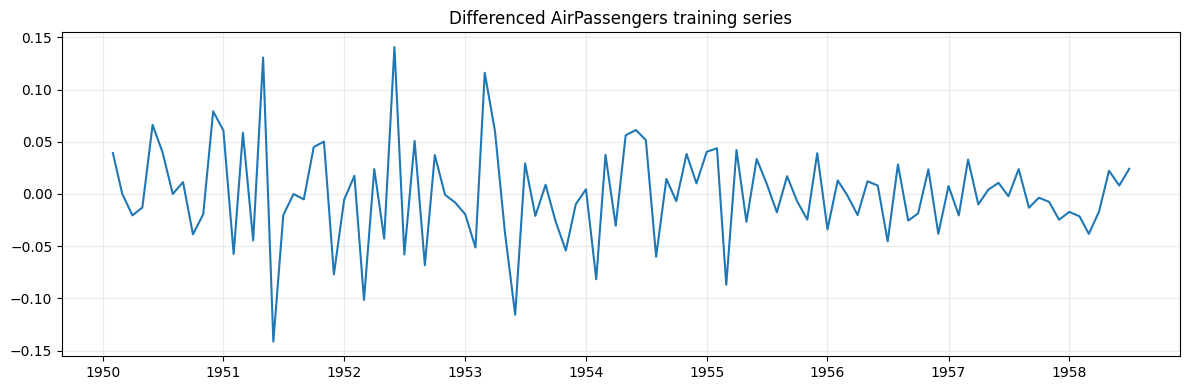

In [ ]:
SELECTED_D = 1
SELECTED_D_SEASONAL = 1
SEASONAL_PERIOD = 12

stationary_train = air_train_analysis.copy()

for _ in range(SELECTED_D):
    stationary_train = stationary_train.diff(1)

for _ in range(SELECTED_D_SEASONAL):
    stationary_train = stationary_train.diff(SEASONAL_PERIOD)

stationary_train = stationary_train.dropna()

if stationary_train.isna().any() or stationary_train.empty:
    raise ValueError("Chuỗi sau sai phân rỗng hoặc còn missing values.")

print(f"Selected d={SELECTED_D}, D={SELECTED_D_SEASONAL}, s={SEASONAL_PERIOD}")
print(f"Transformed observations: {len(stationary_train)}")
print(f"First timestamp: {stationary_train.index.min()}")
print(f"Last timestamp: {stationary_train.index.max()}")

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(stationary_train.index, stationary_train)
ax.set_title("Differenced AirPassengers training series")
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

### ACF/PACF để đề xuất candidate

C:\Users\PC\AppData\Local\Temp\ipykernel_10196\242495044.py:7: FutureWarning: acf currently returns a plain tuple whose length depends on the qstat and alpha arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an AcfResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  acf_values, acf_confint = acf(


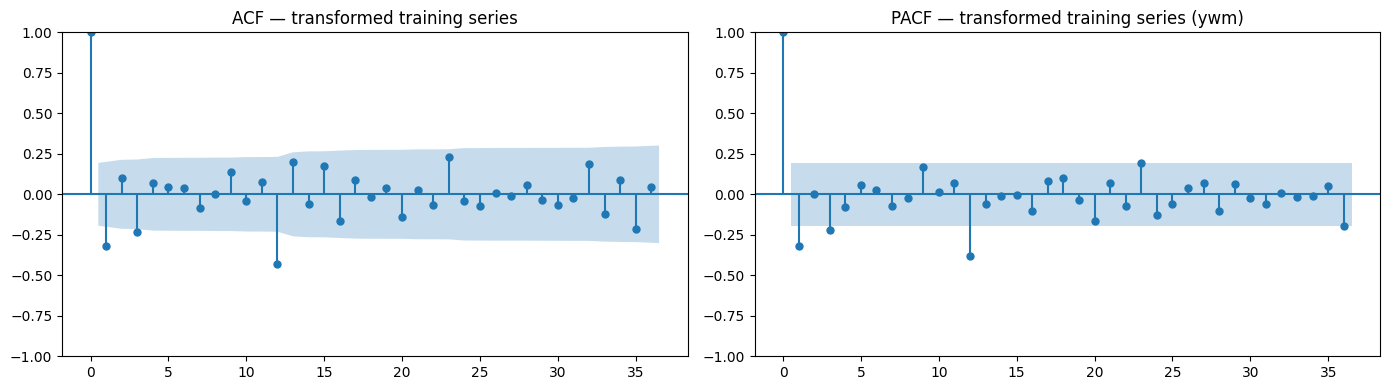

ACF significant lags, excluding lag 0:


,lag,correlation,ci_lower,ci_upper,significant
1,1,-0.320677,-0.514743,-0.126612,True
3,3,-0.232934,-0.447858,-0.018010,True
12,12,-0.429978,-0.661059,-0.198898,True


PACF significant lags, excluding lag 0:


,lag,correlation,ci_lower,ci_upper,significant
1,1,-0.320677,-0.514743,-0.126612,True
3,3,-0.223399,-0.417464,-0.029334,True
12,12,-0.383332,-0.577397,-0.189266,True
23,23,0.195020,0.000955,0.389085,True
36,36,-0.195495,-0.389561,-0.001430,True


Seasonal reference lags:


,lag,correlation,ci_lower,ci_upper,significant
12,12,-0.429978,-0.661059,-0.198898,True
24,24,-0.038973,-0.324378,0.246432,False
36,36,0.044010,-0.257094,0.345114,False


,lag,correlation,ci_lower,ci_upper,significant
12,12,-0.383332,-0.577397,-0.189266,True
24,24,-0.130721,-0.324787,0.063344,False
36,36,-0.195495,-0.389561,-0.001430,True


In [62]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import acf, pacf

if len(stationary_train) <= 36:
    raise ValueError("Không đủ quan sát để tính đến lag 36.")

acf_values, acf_confint = acf(
    stationary_train,
    nlags=36,
    alpha=0.05,
    fft=False,
)
pacf_values, pacf_confint = pacf(
    stationary_train,
    nlags=36,
    alpha=0.05,
    method="ywm",
)

acf_table = pd.DataFrame({
    "lag": np.arange(len(acf_values)),
    "correlation": acf_values,
    "ci_lower": acf_confint[:, 0],
    "ci_upper": acf_confint[:, 1],
})
acf_table["significant"] = (
    (acf_table["ci_lower"] > 0) | (acf_table["ci_upper"] < 0)
)

pacf_table = pd.DataFrame({
    "lag": np.arange(len(pacf_values)),
    "correlation": pacf_values,
    "ci_lower": pacf_confint[:, 0],
    "ci_upper": pacf_confint[:, 1],
})
pacf_table["significant"] = (
    (pacf_table["ci_lower"] > 0) | (pacf_table["ci_upper"] < 0)
)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
plot_acf(stationary_train, lags=36, alpha=0.05, ax=axes[0])
plot_pacf(stationary_train, lags=36, alpha=0.05, method="ywm", ax=axes[1])
axes[0].set_title("ACF — transformed training series")
axes[1].set_title("PACF — transformed training series (ywm)")
plt.tight_layout()
plt.show()

print("ACF significant lags, excluding lag 0:")
display(acf_table.loc[(acf_table["lag"] > 0) & acf_table["significant"]])

print("PACF significant lags, excluding lag 0:")
display(pacf_table.loc[(pacf_table["lag"] > 0) & pacf_table["significant"]])

print("Seasonal reference lags:")
display(
    acf_table.loc[acf_table["lag"].isin([12, 24, 36])],
)
display(
    pacf_table.loc[pacf_table["lag"].isin([12, 24, 36])],
)

### Đề xuất SARIMA candidates từ ACF/PACF

Chuỗi dùng để phân tích là chuỗi training sau sai phân thường và sai phân mùa vụ (`d=1`, `D=1`, `s=12`). Ở các lag ngắn, ACF và PACF đều có spike đáng kể tại lag 1 và lag 3. Tại lag mùa vụ 12, cả ACF (`-0.430`) và PACF (`-0.383`) đều có spike đáng kể. ACF tại lag 24 và 36 không có ý nghĩa; PACF có thêm spike tại lag 23 và 36.

Các đồ thị không cho thấy cutoff ngắn, rõ ràng ở mọi lag, vì vậy không thể suy ra duy nhất các bậc mô hình. Dựa trên spike lag 1 và lag 12, đề xuất provisional hai cấu hình để kiểm tra:

1. **ARIMA baseline:** `ARIMA(1,1,1)` — dùng cùng cấu trúc non-seasonal để làm baseline so sánh.
2. **SARIMA candidate:** `SARIMA(1,1,1)(0,1,1,12)` — thành phần non-seasonal giữ giống ARIMA baseline; seasonal MA bậc 1 được đề xuất từ spike ACF tại lag 12.

Đây là các candidate ban đầu, không phải mô hình cuối cùng. PACF cũng có spike đáng kể ở lag 12 và 36, nên seasonal AR có thể cần xem xét nếu residual diagnostics cho thấy còn cấu trúc mùa vụ. Cần đánh giá convergence, AIC/BIC và residuals trên training data, sau đó so sánh forecast ARIMA và SARIMA trên cùng test horizon bằng MAE/RMSE.

In [63]:
import warnings

from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX

p = 1
q = 1
P = 0
Q = 1

arima_order = (p, SELECTED_D, q)
sarima_order = (p, SELECTED_D, q)
sarima_seasonal_order = (P, SELECTED_D_SEASONAL, Q, SEASONAL_PERIOD)

if ANALYSIS_SCALE == "log":
    train_model = np.log(air_train)
else:
    train_model = air_train.copy()

model_specs = {
    "ARIMA": lambda: ARIMA(train_model, order=arima_order).fit(),
    "SARIMA": lambda: SARIMAX(
        train_model,
        order=sarima_order,
        seasonal_order=sarima_seasonal_order,
    ).fit(disp=False),
}

fitted_models = {}
fit_rows = []

for model_name, fit_function in model_specs.items():
    with warnings.catch_warnings(record=True) as caught_warnings:
        warnings.simplefilter("always")
        fitted = fit_function()

    fitted_models[model_name] = fitted
    mle_info = getattr(fitted, "mle_retvals", {})

    fit_rows.append({
        "model": model_name,
        "order": arima_order if model_name == "ARIMA" else sarima_order,
        "seasonal_order": None if model_name == "ARIMA" else sarima_seasonal_order,
        "converged": mle_info.get("converged"),
        "AIC": fitted.aic,
        "BIC": fitted.bic,
        "warnings": " | ".join(str(item.message) for item in caught_warnings),
    })

fit_results = pd.DataFrame(fit_rows)
display(fit_results)

,model,order,seasonal_order,converged,AIC,BIC,warnings
0,ARIMA,"(1, 1, 1)",None,True,-197.221464,-189.012869,
1,SARIMA,"(1, 1, 1)","(0, 1, 1, 12)",True,-369.862160,-359.362269,


### Residual diagnostics

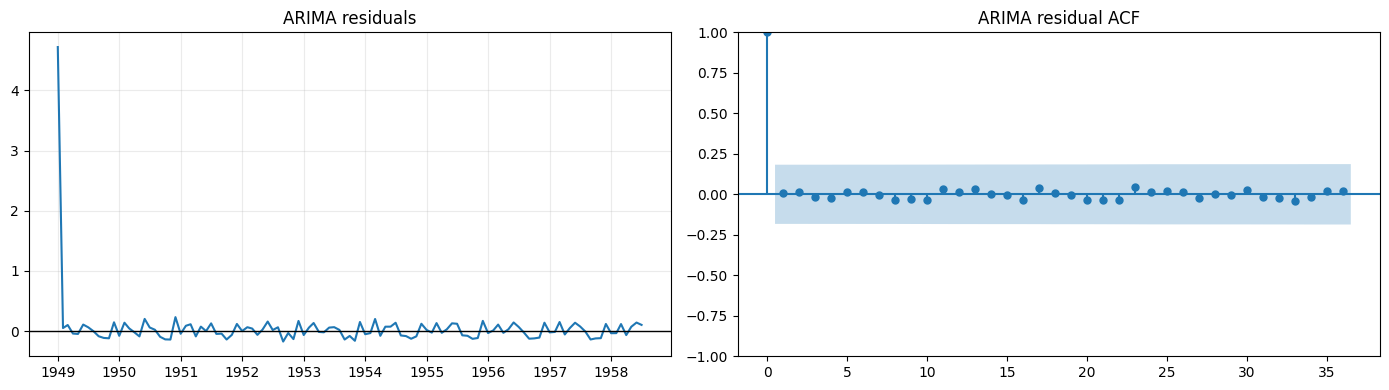

ARIMA Ljung–Box:


,lb_stat,lb_pvalue
12,0.742433,0.999957
24,2.174949,1.000000


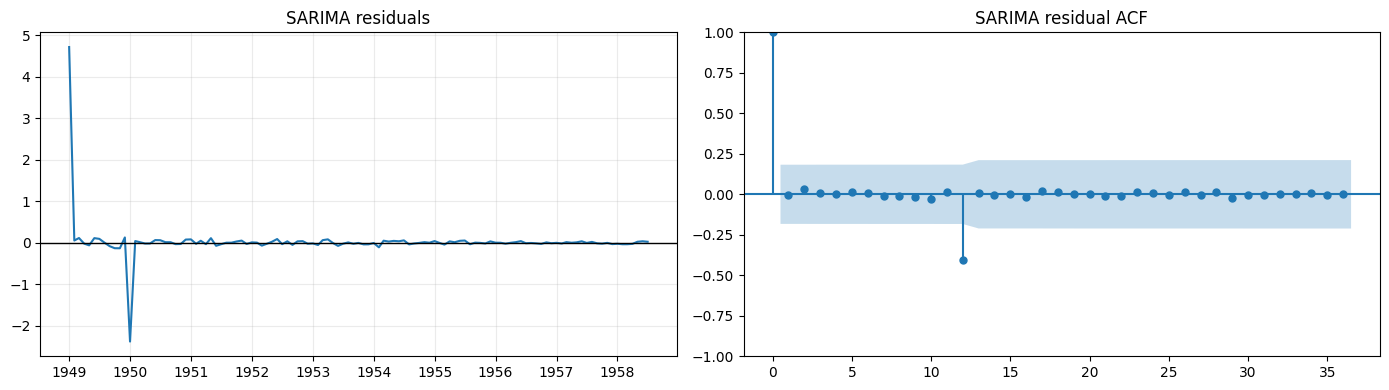

SARIMA Ljung–Box:


,lb_stat,lb_pvalue
12,21.663230,0.010010
24,21.846599,0.408396


In [64]:
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.stats.diagnostic import acorr_ljungbox

residual_results = []

for model_name, fitted in fitted_models.items():
    residuals = pd.Series(
        np.asarray(fitted.resid),
        index=train_model.index,
        name=f"{model_name}_residual",
    ).dropna()

    model_df = p + q
    if model_name == "SARIMA":
        model_df += P + Q

    valid_lags = [
        lag for lag in [12, 24]
        if lag > model_df and lag < len(residuals)
    ]

    if not valid_lags:
        raise ValueError("Không có Ljung–Box lag hợp lệ cho model_df và residual length.")

    lb_results = acorr_ljungbox(
        residuals,
        lags=valid_lags,
        model_df=model_df,
        return_df=True,
    )

    residual_results.append({
        "model": model_name,
        "residual_mean": residuals.mean(),
        "ljung_box": lb_results,
    })

    fig, axes = plt.subplots(1, 2, figsize=(14, 4))
    axes[0].plot(residuals.index, residuals)
    axes[0].axhline(0, color="black", linewidth=1)
    axes[0].set_title(f"{model_name} residuals")
    axes[0].grid(alpha=0.25)

    plot_acf(
        residuals,
        lags=min(36, len(residuals) - 1),
        alpha=0.05,
        ax=axes[1],
    )
    axes[1].set_title(f"{model_name} residual ACF")

    plt.tight_layout()
    plt.show()

    print(f"{model_name} Ljung–Box:")
    display(lb_results)

Ljung–Box được kiểm tra tại lag 12 và 24 với mức ý nghĩa 0.05. Với ARIMA, p-value lần lượt là `0.999957` và `1.000000`; do cả hai đều lớn hơn 0.05, chưa có bằng chứng về tự tương quan ở các lag được kiểm tra. Với SARIMA, p-value tại lag 12 là `0.010010` (< 0.05), cho thấy residual vẫn còn tự tương quan ở lag này; tại lag 24, p-value là `0.408396` (> 0.05).

### Forecast cùng test horizon và so sánh MAE/RMSE

,model,MAE,RMSE
0,ARIMA,84.254386,96.327568
1,SARIMA,12.165113,14.917604


,model,date,actual,forecast,absolute_error
0,ARIMA,1958-11-01,310.0,496.108123,186.108123
1,SARIMA,1960-03-01,419.0,452.003028,33.003028


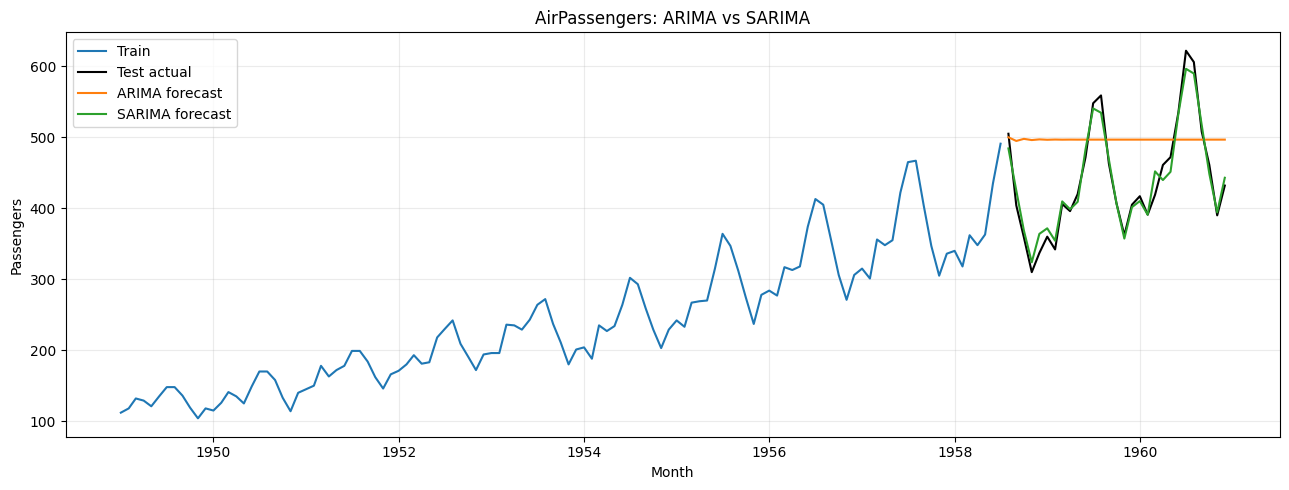

In [66]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

forecast_series = {}

for model_name, fitted in fitted_models.items():
    forecast = fitted.get_forecast(steps=len(air_test)).predicted_mean

    if len(forecast) != len(air_test):
        raise ValueError(f"{model_name}: forecast length không bằng test length.")
    if not forecast.index.equals(air_test.index):
        raise ValueError(f"{model_name}: forecast index không khớp test index.")

    forecast_values = np.asarray(forecast, dtype=float)

    if ANALYSIS_SCALE == "log":
        forecast_values = np.exp(forecast_values)

    forecast_series[model_name] = pd.Series(
        forecast_values,
        index=air_test.index,
        name=f"{model_name}_forecast",
    )

metric_rows = []
error_rows = []

for model_name, forecast in forecast_series.items():
    errors = air_test - forecast

    metric_rows.append({
        "model": model_name,
        "MAE": mean_absolute_error(air_test, forecast),
        "RMSE": np.sqrt(mean_squared_error(air_test, forecast)),
    })

    largest_error_date = errors.abs().idxmax()
    error_rows.append({
        "model": model_name,
        "date": largest_error_date,
        "actual": air_test.loc[largest_error_date],
        "forecast": forecast.loc[largest_error_date],
        "absolute_error": abs(errors.loc[largest_error_date]),
    })

metrics_comparison = pd.DataFrame(metric_rows)
largest_errors = pd.DataFrame(error_rows)

display(metrics_comparison)
display(largest_errors)

fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(air_train.index, air_train, label="Train")
ax.plot(air_test.index, air_test, label="Test actual", color="black")
for model_name, forecast in forecast_series.items():
    ax.plot(forecast.index, forecast, label=f"{model_name} forecast")

ax.set_title("AirPassengers: ARIMA vs SARIMA")
ax.set_xlabel("Month")
ax.set_ylabel("Passengers")
ax.legend()
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

### So sánh ARIMA và SARIMA trên AirPassengers

Hai mô hình được đánh giá trên cùng tập test gồm 29 tháng (08/1958–12/1960), với dự báo được đưa về thang số hành khách gốc.

| Mô hình | MAE | RMSE |
|---|---:|---:|
| ARIMA(1,1,1) | 84.254 | 96.328 |
| SARIMA(1,1,1)(0,1,1,12) | 12.165 | 14.918 |

SARIMA có MAE và RMSE thấp hơn ARIMA trên tập test này. Đồ thị cũng cho thấy forecast ARIMA gần như phẳng quanh mức 500 hành khách, nên không theo sát các biến động theo mùa trong giai đoạn test. Forecast SARIMA bám các đỉnh và đáy theo mùa tốt hơn, gần với chuỗi thực tế hơn.

Kết quả này cho thấy việc thêm thành phần mùa vụ giúp cải thiện đáng kể dự báo AirPassengers trên holdout đang xét. Tuy nhiên, đây là kết luận giới hạn trong dataset, cách chia train/test và forecast horizon này; không thể suy rộng thành SARIMA luôn tốt hơn ARIMA.

Residual diagnostics cũng cần được cân nhắc: Ljung–Box của SARIMA tại lag 12 có p-value `0.010010` (< 0.05), gợi ý residual vẫn còn tự tương quan ở lag đó. Vì vậy, dù SARIMA có forecast metrics tốt hơn, vẫn còn cấu trúc trong residual cần xem xét; chưa thể kết luận mô hình đã mô tả hoàn toàn chuỗi.

## Tổng kết — Bài tập nâng cao SARIMA với AirPassengers

### 1. Dữ liệu và holdout

AirPassengers có 144 quan sát tháng, từ tháng 01/1949 đến tháng 12/1960. Dữ liệu được chia theo thứ tự thời gian, không shuffle:

- **Train:** 115 quan sát, từ 01/1949 đến 07/1958.
- **Test:** 29 quan sát, từ 08/1958 đến 12/1960.

Test set được dành cho bước đánh giá forecast.

### 2. Scale và tính dừng

Biểu đồ training cho thấy biên độ dao động tăng theo mức hành khách ở thang gốc. Trên thang log, dao động có vẻ ổn định hơn, nên chọn **natural-log scale** cho phân tích. Log-transform không tự loại bỏ trend hay seasonality; các yếu tố này được đánh giá riêng bằng ADF và differencing.

ADF trên chuỗi log training ban đầu cho statistic `-1.574027`, p-value `0.496626`; chưa đủ bằng chứng bác bỏ giả thuyết chuỗi có unit root tại mức ý nghĩa 0.05.

| Chuỗi training | Quan sát | ADF statistic | p-value | Quyết định tại α = 0.05 |
|---|---:|---:|---:|---|
| Chuỗi gốc trên thang log | 115 | -1.574027 | 0.496626 | Chưa bác bỏ H₀ |
| Sai phân thường (`d=1`) | 114 | -2.635851 | 0.085812 | Chưa bác bỏ H₀ |
| Sai phân mùa vụ (`D=1, s=12`) | 103 | -1.991013 | 0.290527 | Chưa bác bỏ H₀ |
| Kết hợp (`d=1, D=1, s=12`) | 102 | -3.946340 | 0.001719 | Bác bỏ H₀ |

Sai phân thường hoặc sai phân mùa vụ riêng lẻ chưa đạt mức ý nghĩa 0.05. Chuỗi sai phân kết hợp có p-value `0.001719`, hỗ trợ tính dừng theo ADF. Vì vậy, dùng cấu hình `d=1`, `D=1`, `s=12` để tiếp tục nhận diện mô hình. Chuỗi sau sai phân có 102 quan sát, từ 02/1950 đến 07/1958.

### 3. ACF/PACF và candidate

Trên chuỗi training đã sai phân kết hợp:

- **ACF:** lag 1 (`-0.321`), lag 3 (`-0.233`) và lag 12 (`-0.430`) có ý nghĩa.
- **PACF:** lag 1 (`-0.321`), lag 3 (`-0.223`), lag 12 (`-0.383`), lag 23 (`0.195`) và lag 36 (`-0.195`) có ý nghĩa.
- Trong các seasonal reference lags, ACF có spike tại lag 12 nhưng không có ý nghĩa tại lag 24 và 36. PACF có spike tại lag 12 và 36; lag 24 không có ý nghĩa.

Các pattern này là evidence để đề xuất candidate, không xác định duy nhất order tối ưu. Hai mô hình được fit là:

- **ARIMA baseline:** `ARIMA(1,1,1)`.
- **Seasonal model:** `SARIMA(1,1,1)(0,1,1,12)`.

Hai mô hình dùng cùng cấu trúc non-seasonal và cùng training scale; SARIMA bổ sung thành phần seasonal để kiểm tra khả năng mô hình hóa chu kỳ 12 tháng.

### 4. Kết quả fit

| Mô hình | Order | Seasonal order | Hội tụ | AIC | BIC | Warning ghi nhận |
|---|---|---|---|---:|---:|---|
| ARIMA | (1,1,1) | — | Có | -197.221464 | -189.012869 | Không |
| SARIMA | (1,1,1) | (0,1,1,12) | Có | -369.862160 | -359.362269 | Không |

Cả hai mô hình đều hội tụ và không ghi nhận warning trong output fit. Không nên so sánh AIC/BIC một cách máy móc giữa các mô hình có cấu trúc sai phân khác nhau; đánh giá forecast trên cùng holdout cũng cần được xem xét.

### 5. Residual diagnostics

Ljung–Box được kiểm tra tại lag 12 và 24, mức ý nghĩa 0.05:

| Mô hình | Lag 12 p-value | Lag 24 p-value |
|---|---:|---:|
| ARIMA | 0.999957 | 1.000000 |
| SARIMA | 0.010010 | 0.408396 |

Với ARIMA, chưa có bằng chứng tự tương quan ở các lag được kiểm tra vì cả hai p-value đều lớn hơn 0.05. Với SARIMA, p-value tại lag 12 là `0.010010` (< 0.05), cho thấy residuals vẫn còn tự tương quan ở lag này; p-value tại lag 24 là `0.408396` (> 0.05).

Do đó, chưa thể kết luận residuals của cả hai mô hình hoàn toàn là white noise. Đặc biệt, cần lưu ý cấu trúc còn lại tại lag 12 của SARIMA và xem thêm residual ACF/đồ thị. Residual mean không được hiển thị trong output bảng hiện tại nên chưa kết luận về mean được.

### 6. Forecast và đánh giá

Forecast được so sánh với cùng 29 quan sát test trên thang hành khách:

| Mô hình | MAE | RMSE |
|---|---:|---:|
| ARIMA | 84.254386 | 96.327568 |
| SARIMA | 12.165113 | 14.917604 |

Trong holdout này, SARIMA có MAE và RMSE thấp hơn ARIMA. Sai lệch tuyệt đối lớn nhất:

- **ARIMA:** 11/1958 — actual `310`, forecast `496.108`, absolute error `186.108`.
- **SARIMA:** 03/1960 — actual `419`, forecast `452.003`, absolute error `33.003`.

### Kết luận

Trên AirPassengers và holdout đã dùng, SARIMA có MAE/RMSE thấp hơn đáng kể so với ARIMA baseline, cho thấy seasonal modeling có ích cho forecast trong lần đánh giá này. Tuy nhiên, Ljung–Box cho thấy SARIMA vẫn còn tự tương quan residual tại lag 12; vì vậy chưa thể coi residuals là white noise hoặc kết luận mô hình hoàn hảo. Kết luận chỉ áp dụng cho dataset, cấu hình và test horizon này; cần cân nhắc residual diagnostics trước khi chốt mô hình.